In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
data=pd.read_csv('netflix_titles.csv')
data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [41]:
data.info()
data.shape
data.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [42]:
data.isnull().sum

<bound method DataFrame.sum of       show_id   type  title  director   cast  country  date_added  \
0       False  False  False     False   True    False       False   
1       False  False  False      True  False    False       False   
2       False  False  False     False  False     True       False   
3       False  False  False      True   True     True       False   
4       False  False  False      True  False    False       False   
...       ...    ...    ...       ...    ...      ...         ...   
8802    False  False  False     False  False    False       False   
8803    False  False  False      True   True     True       False   
8804    False  False  False     False  False    False       False   
8805    False  False  False     False  False    False       False   
8806    False  False  False     False  False    False       False   

      release_year  rating  duration  listed_in  description  
0            False   False     False      False        False  
1            False   False     False      False        False  
2            False   False     False      False        False  
3            False   False     False      False        False  
4            False   False     False      False        False  
...            ...     ...       ...        ...          ...  
8802         False   False     False      False        False  
8803         False   False     False      False        False  
8804         False   False     False      False        False  
8805         False   False     False      False        False  
8806         False   False     False      False        False  

[8807 rows x 12 columns]>

In [43]:
data['director'].fillna('Unknown', inplace=True)
data['cast'].fillna('Unknown', inplace=True)
data['country'].fillna('Unknown', inplace=True)
data['rating'].fillna('Not Rated', inplace=True)

/tmp/ipykernel_709/543238936.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['director'].fillna('Unknown', inplace=True)
/tmp/ipykernel_709/543238936.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

In [44]:
data['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


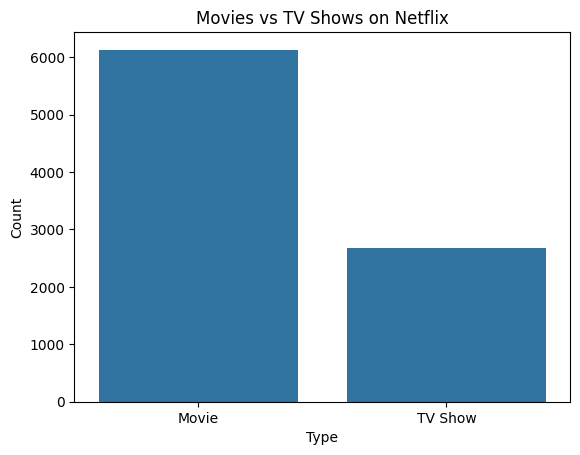

In [45]:
sns.countplot(x='type', data=data)

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Count")

plt.show()

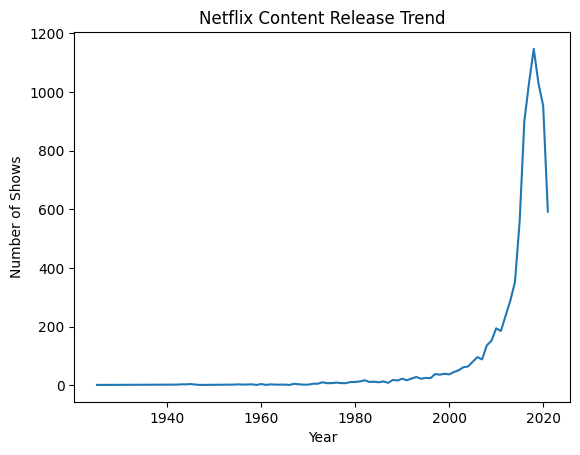

In [46]:
release_year = data['release_year'].value_counts().sort_index()

release_year.plot(kind='line')

plt.title("Netflix Content Release Trend")
plt.xlabel("Year")
plt.ylabel("Number of Shows")

plt.show()

Text(0, 0.5, 'Number of Shows')

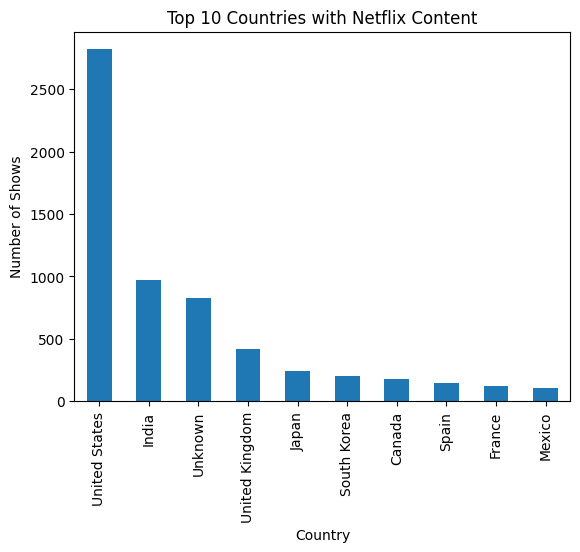

In [47]:
top_country=data['country'].value_counts().head(10)
top_country.plot(kind='bar')

plt.title("Top 10 Countries with Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Shows")

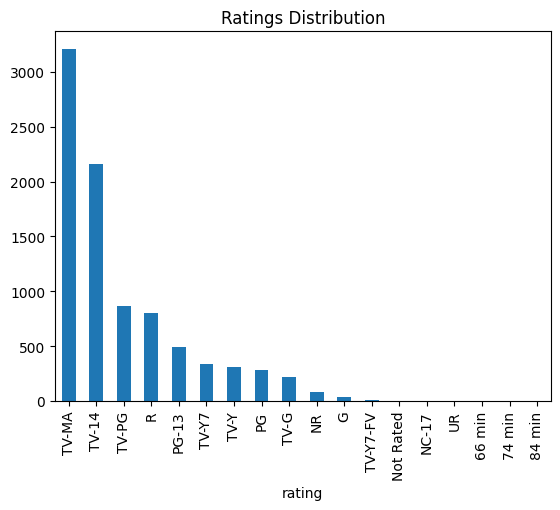

In [48]:
data['rating'].value_counts().plot(kind='bar')

plt.title("Ratings Distribution")

plt.show()

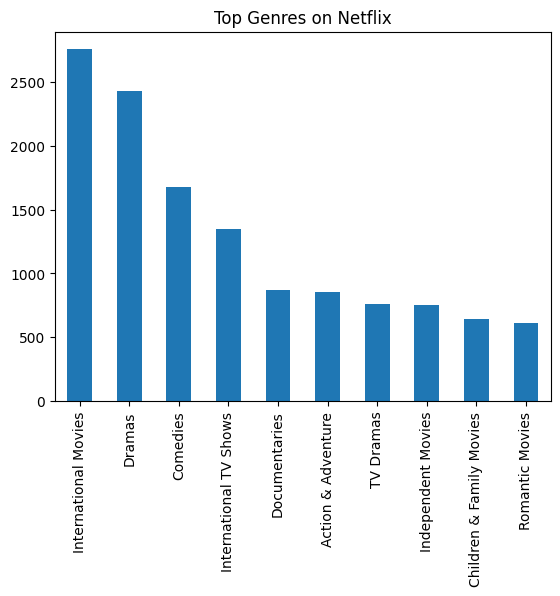

In [49]:
genres = data['listed_in'].str.split(', ', expand=True).stack()

genres.value_counts().head(10).plot(kind='bar')

plt.title("Top Genres on Netflix")

plt.show()

In [60]:

data['year_added'] = data['date_added'].dt.year

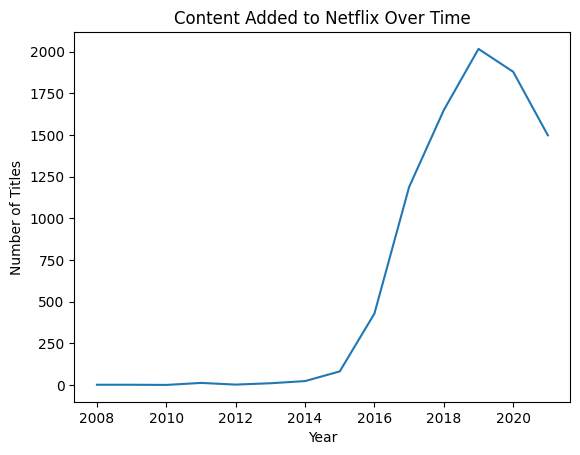

In [59]:
data['date_added'] = pd.to_datetime(data['date_added'], format='mixed', errors='coerce')
data['year_added'] = data['date_added'].dt.year

content_added = data['year_added'].value_counts().sort_index()

content_added.plot(kind='line')

plt.title("Content Added to Netflix Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Titles")

plt.show()

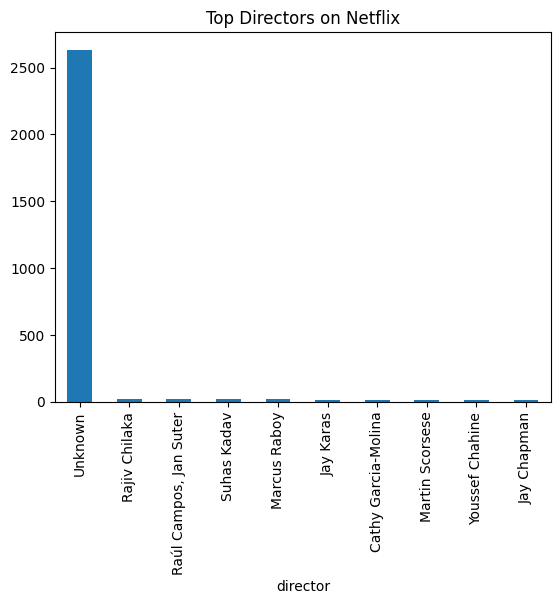

In [53]:
top_directors = data['director'].value_counts().head(10)

top_directors.plot(kind='bar')

plt.title("Top Directors on Netflix")

plt.show()

In [52]:
movies = data[data['type'] == 'Movie']

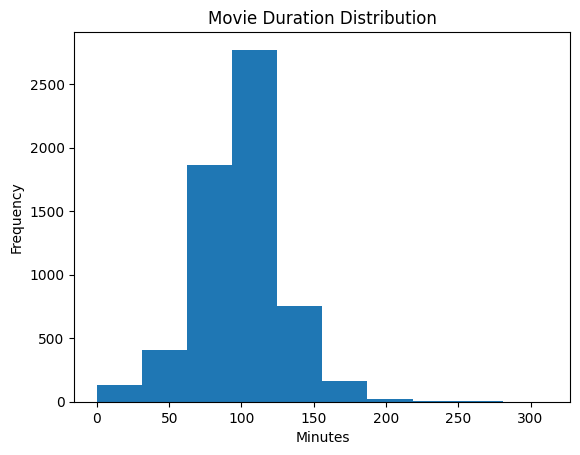

In [51]:
plt.hist(movies['duration'])

plt.title("Movie Duration Distribution")
plt.xlabel("Minutes")
plt.ylabel("Frequency")

plt.show()